# Robustez da LSTM a Sementes Aleatórias — Arroz e Trigo

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Os notebooks `lstm_arroz.ipynb` e `lstm_trigo.ipynb` treinam a LSTM em diferenças **uma única vez**, com a semente 42. Mas o resultado de
uma rede neural depende da **inicialização aleatória** dos pesos, da ordem em que as janelas são embaralhadas e do *dropout*: outra semente
pode levar a outro mínimo da função de perda e, na previsão recursiva de 30 dias, a outra **inclinação** projetada.

Este notebook repete o experimento com **10 sementes** (42 e 1 a 9) nas duas culturas, mantendo **todo o resto idêntico**: mesmos dados,
divisão treino/teste, `lookback`, arquitetura, hiperparâmetros, `EarlyStopping` e previsão recursiva de 30 passos com alvo em diferenças.
A pergunta é: **a vantagem da LSTM sobre o SARIMA/SARIMAX se mantém para qualquer semente, ou depende da semente 42?**

Roteiro:
1. Pipeline (idêntico aos notebooks de cada cultura) e verificação de reprodutibilidade com a semente 42
2. Treinamento com 10 sementes por cultura
3. Distribuição das métricas e comparação com SARIMA, SARIMAX e os modelos ingênuos
4. Trajetórias previstas e média das sementes (*ensemble*)
5. Exportação e conclusão

In [1]:
# Bibliotecas
import os
import time
import warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # esconde mensagens internas do TensorFlow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.config.experimental.enable_op_determinism()   # mesma semente -> mesmo resultado

PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

SEMENTES   = [42] + list(range(1, 10))   # a 42 é a dos notebooks de cada cultura
FIM_TREINO = "2026-01-31"
HORIZONTE  = 30
LOOKBACK   = 30
ALVO, DELTA = "preco_brl", "delta_preco_brl"

CULTURAS = {
    "arroz": {
        "dados": "../data/processed/dataset_final_arroz.csv", "unidade": "R$/saca", "ylim": (52, 57),
        "sarima":  ("metricas_sarima_arroz.csv",  "SARIMA"),
        "sarimax": ("metricas_sarimax_arroz.csv", "SARIMAX"),
        "semente42": "metricas_lstm_semente42_arroz.csv",
    },
    "trigo": {
        "dados": "../data/processed/dataset_final_trigo.csv", "unidade": "R$/t", "ylim": (950, 1170),
        "sarima":  ("metricas_sarima_trigo.csv",  "SARIMA(1,1,1)(1,0,1)[7]"),
        "sarimax": ("metricas_sarimax_trigo.csv", "SARIMAX(1,1,1)(1,0,1)[7] + Paridade (lag 7) (aprimorado)"),
        "semente42": "metricas_lstm_semente42_trigo.csv",
    },
}
print(f"TensorFlow {tf.__version__} | {len(SEMENTES)} sementes: {SEMENTES}")

TensorFlow 2.21.0 | 10 sementes: [42, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 1. Pipeline

As funções abaixo reproduzem, passo a passo, as seções 1 a 5 dos notebooks de cada cultura: alvo $\Delta P_t = P_t - P_{t-1}$, 37 variáveis
de entrada, `MinMaxScaler` ajustado só no treino, janelas de 30 dias, LSTM(64) + Dropout(0,2) + Dense(1), Adam(0,001), MSE,
`EarlyStopping(patience=15)` com 10% de validação, e previsão recursiva de 30 passos com reconstrução do preço e recálculo das variáveis
derivadas. A única coisa que muda entre as execuções é a semente, fixada com `keras.utils.set_random_seed` imediatamente antes de construir a rede.

In [2]:
PRECO_LAGS, PRECO_JANELAS = [1, 7, 14, 30], [7, 14, 30]

def criar_janelas(X, y, lookback):
    Xs, ys, idx = [], [], []
    for i in range(lookback, len(X)):
        Xs.append(X[i - lookback:i]); ys.append(y[i]); idx.append(i)
    return np.array(Xs), np.array(ys), np.array(idx)

def preparar(cultura):
    cfg = CULTURAS[cultura]
    dados = pd.read_csv(cfg["dados"], parse_dates=["data"], index_col="data").sort_index().asfreq("D")
    dados[DELTA] = dados[ALVO] - dados["preco_brl_lag_1"]
    features = [c for c in dados.columns if c != ALVO]
    treino = dados.loc[:FIM_TREINO]
    teste  = dados.loc["2026-02-01":].iloc[:HORIZONTE]

    escala_X = MinMaxScaler(feature_range=(0, 1)).fit(treino[features])
    escala_y = MinMaxScaler(feature_range=(0, 1)).fit(treino[[DELTA]])
    X_esc = escala_X.transform(dados.loc[:teste.index[-1], features])
    y_esc = escala_y.transform(dados.loc[:teste.index[-1], [DELTA]]).ravel()

    X_seq, y_seq, idx = criar_janelas(X_esc, y_esc, LOOKBACK)
    eh_treino = idx < len(treino)
    return {"dados": dados, "features": features, "treino": treino, "teste": teste,
            "escala_X": escala_X, "escala_y": escala_y,
            "X_tr": X_seq[eh_treino], "y_tr": y_seq[eh_treino], "X_te": X_seq[~eh_treino]}

def treinar(p, semente):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semente)          # Python, NumPy e TensorFlow
    modelo = keras.Sequential([
        layers.Input(shape=(LOOKBACK, len(p["features"]))),
        layers.LSTM(64, return_sequences=False),
        layers.Dropout(0.2),
        layers.Dense(1),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    hist = modelo.fit(p["X_tr"], p["y_tr"], epochs=200, batch_size=32, validation_split=0.1,
                      shuffle=True, callbacks=[parada], verbose=0)
    return modelo, hist.history

def atualizar_derivadas(df, data):
    pr  = df[ALVO]
    pos = df.index.get_loc(data)
    df.at[data, "preco_usd"] = pr.iloc[pos] / df.at[data, "dolar_venda"]
    df.at[data, DELTA]       = pr.iloc[pos] - pr.iloc[pos - 1]
    for k in PRECO_LAGS:
        df.at[data, f"preco_brl_lag_{k}"] = pr.iloc[pos - k]
    for w in PRECO_JANELAS:
        janela = pr.iloc[pos - w + 1:pos + 1]
        df.at[data, f"preco_brl_ma_{w}"]  = janela.mean()
        df.at[data, f"preco_brl_std_{w}"] = janela.std()

def prever_recursivo(modelo, p):
    datas = p["teste"].index
    df = p["dados"].loc[:datas[-1]].copy()
    df.loc[datas, ALVO] = np.nan
    precos = []
    for d in datas:
        janela = df.loc[d - pd.Timedelta(days=LOOKBACK):d - pd.Timedelta(days=1), p["features"]]
        x = p["escala_X"].transform(janela)[np.newaxis]
        delta_hat = float(p["escala_y"].inverse_transform(modelo.predict(x, verbose=0))[0, 0])
        df.at[d, ALVO] = df.at[d - pd.Timedelta(days=1), ALVO] + delta_hat
        atualizar_derivadas(df, d)
        precos.append(df.at[d, ALVO])
    return pd.Series(precos, index=datas)

def metricas(y_real, y_hat):
    erro = np.asarray(y_real) - np.asarray(y_hat)
    return {"RMSE": np.sqrt(np.mean(erro ** 2)), "MAE": np.mean(np.abs(erro)),
            "MAPE": np.mean(np.abs(erro / np.asarray(y_real))) * 100}

def ganho_validacao(modelo, p):
    # Ganho de MSE da variação prevista (1 passo) sobre "prever sempre a variação média do treino", na validação do Keras
    corte = int(len(p["X_tr"]) * (1 - 0.1))
    real  = p["escala_y"].inverse_transform(p["y_tr"][corte:].reshape(-1, 1)).ravel()
    prev  = p["escala_y"].inverse_transform(modelo.predict(p["X_tr"][corte:], verbose=0)).ravel()
    media = p["treino"][DELTA].iloc[:LOOKBACK + corte].mean()
    return 1 - np.mean((real - prev) ** 2) / np.mean((real - media) ** 2)

PREP = {c: preparar(c) for c in CULTURAS}
for c, p in PREP.items():
    print(f"{c:<6} X_treino {p['X_tr'].shape} | X_teste {p['X_te'].shape} | teste {p['teste'].index[0]:%d/%m/%Y} a {p['teste'].index[-1]:%d/%m/%Y}")

arroz  X_treino (6545, 30, 37) | X_teste (30, 30, 37) | teste 01/02/2026 a 02/03/2026
trigo  X_treino (6545, 30, 37) | X_teste (30, 30, 37) | teste 01/02/2026 a 02/03/2026


## 2. Treinamento com 10 sementes

Para cada cultura e semente registramos as métricas da previsão recursiva de 30 dias (no preço reconstruído), as épocas de treino,
a **inclinação** média projetada (R\$ por dia) e o **ganho na validação** — quanto a rede reduz o MSE da variação diária em relação a prever sempre
a variação média do treino (valores ≤ 0 indicam que a rede não aprendeu nada além da média).

A semente 42 deve reproduzir **exatamente** o resultado dos notebooks de cada cultura (`metricas_lstm_semente42_<cultura>.csv`); isso garante que o pipeline
deste notebook é o mesmo dos notebooks originais.

In [3]:
linhas, trajetorias = [], {}
inicio = time.time()
for cultura, p in PREP.items():
    P_T = p["treino"][ALVO].iloc[-1]
    y_teste = p["teste"][ALVO]
    for s in SEMENTES:
        t0 = time.time()
        modelo, hist = treinar(p, s)
        y_prev = prever_recursivo(modelo, p)
        trajetorias[(cultura, s)] = y_prev
        linhas.append({"cultura": cultura, "semente": s, **metricas(y_teste, y_prev),
                       "inclinacao_dia": (y_prev.iloc[-1] - P_T) / HORIZONTE,
                       "ganho_validacao": ganho_validacao(modelo, p),
                       "epocas": len(hist["loss"]), "melhor_epoca": int(np.argmin(hist["val_loss"])) + 1})
        print(f"{cultura:<6} semente {s:>2}: RMSE = {linhas[-1]['RMSE']:8.4f} | inclinação = {linhas[-1]['inclinacao_dia']:+.3f}/dia | "
              f"épocas = {linhas[-1]['epocas']:>3} | {time.time() - t0:5.0f}s")
        if s == 42:   # reprodutibilidade: a semente 42 tem de bater com o resultado do notebook da cultura
            oficial = pd.read_csv(f"{PASTA_SAIDA}/{CULTURAS[cultura]['semente42']}").iloc[0]["RMSE"]
            print(f"       -> resultado do notebook lstm_{cultura}.ipynb: RMSE = {oficial:.4f}")
            assert np.isclose(linhas[-1]["RMSE"], oficial, atol=1e-3), "pipeline diferente do notebook original"
print(f"\nTempo total: {(time.time() - inicio) / 60:.1f} min")

resultados = pd.DataFrame(linhas)

arroz  semente 42: RMSE =   0.3435 | inclinação = +0.068/dia | épocas =  27 |    49s
       -> resultado oficial do notebook: RMSE = 0.3435


arroz  semente  1: RMSE =   1.4394 | inclinação = -0.028/dia | épocas =  29 |    32s


arroz  semente  2: RMSE =   1.5313 | inclinação = -0.040/dia | épocas =  19 |    26s


arroz  semente  3: RMSE =   2.9389 | inclinação = -0.111/dia | épocas =  30 |    77s


arroz  semente  4: RMSE =   0.5504 | inclinação = +0.026/dia | épocas =  21 |    58s


arroz  semente  5: RMSE =   1.4062 | inclinação = -0.027/dia | épocas =  24 |    56s


... (10 outputs left out)

trigo  semente  6: RMSE =  20.4949 | inclinação = +0.054/dia | épocas =  66 |   156s


trigo  semente  7: RMSE =  46.2143 | inclinação = -1.453/dia | épocas =  31 |    78s


trigo  semente  8: RMSE =   8.2414 | inclinação = +0.848/dia | épocas =  61 |   142s


trigo  semente  9: RMSE =  28.5262 | inclinação = -0.424/dia | épocas =  49 |   120s

Tempo total: 28.6 min


## 3. Distribuição das métricas e comparação com os demais modelos

Referências (horizonte fechado de 30 dias, mesmo período de teste):

- **SARIMA** e **SARIMAX**: lidos dos CSVs dos notebooks estatísticos de cada cultura (modelos determinísticos, sem variação por semente);
- **Ingênuo**: último preço do treino repetido nos 30 dias;
- **Ingênuo com tendência**: último preço + inclinação média dos últimos 30 dias do treino.

In [4]:
refs = {}
for cultura, cfg in CULTURAS.items():
    p = PREP[cultura]
    y_teste, P_T = p["teste"][ALVO], p["treino"][ALVO].iloc[-1]
    h = np.arange(1, HORIZONTE + 1)
    inclin_30 = (P_T - p["treino"][ALVO].iloc[-31]) / 30
    ensemble = pd.concat([trajetorias[(cultura, s)] for s in SEMENTES], axis=1).mean(axis=1)
    trajetorias[(cultura, "ensemble")] = ensemble
    refs[cultura] = {
        "SARIMA":  pd.read_csv(f"{PASTA_SAIDA}/{cfg['sarima'][0]}").set_index("modelo").loc[cfg["sarima"][1], "RMSE"],
        "SARIMAX": pd.read_csv(f"{PASTA_SAIDA}/{cfg['sarimax'][0]}").set_index("modelo").loc[cfg["sarimax"][1], "RMSE"],
        "Ingênuo": metricas(y_teste, np.full(HORIZONTE, P_T))["RMSE"],
        "Ingênuo com tendência (30 dias)": metricas(y_teste, P_T + inclin_30 * h)["RMSE"],
        "Média das 10 sementes (ensemble)": metricas(y_teste, ensemble)["RMSE"],
    }

resumo = []
for cultura, g in resultados.groupby("cultura", sort=False):
    r = refs[cultura]
    resumo.append({
        "cultura": cultura,
        "RMSE média": g["RMSE"].mean(), "RMSE desvio": g["RMSE"].std(),
        "RMSE mín": g["RMSE"].min(), "RMSE mediana": g["RMSE"].median(), "RMSE máx": g["RMSE"].max(),
        "MAE média": g["MAE"].mean(), "MAPE média (%)": g["MAPE"].mean(),
        "inclinação média (/dia)": g["inclinacao_dia"].mean(), "inclinação desvio": g["inclinacao_dia"].std(),
        "ganho validação médio": g["ganho_validacao"].mean(),
        "sementes < SARIMAX": f"{(g['RMSE'] < r['SARIMAX']).sum()}/{len(g)}",
        "sementes < ingênuo c/ tendência": f"{(g['RMSE'] < r['Ingênuo com tendência (30 dias)']).sum()}/{len(g)}",
        "sementes < ingênuo": f"{(g['RMSE'] < r['Ingênuo']).sum()}/{len(g)}",
        "RMSE ensemble": r["Média das 10 sementes (ensemble)"],
    })
resumo = pd.DataFrame(resumo).set_index("cultura")
print("Referências (RMSE):")
display(pd.DataFrame(refs).round(4))
resumo.T

Referências (RMSE):


,arroz,trigo
SARIMA,0.4658,19.2886
SARIMAX,0.4655,18.2936
Ingênuo,0.9535,20.8903
Ingênuo com tendência (30 dias),0.6281,13.9710
Média das 10 sementes (ensemble),0.8822,20.4055


cultura,arroz,trigo
RMSE média,1.156517,20.726539
RMSE desvio,0.847834,11.253489
RMSE mín,0.306454,6.902584
RMSE mediana,1.102637,20.897233
RMSE máx,2.938894,46.2143
MAE média,0.979364,16.364502
MAPE média (%),1.777175,1.508725
inclinação média (/dia),0.002285,0.052618
inclinação desvio,0.064509,0.687433
ganho validação médio,0.008575,0.028817


In [5]:
resultados.round(4).set_index(["cultura", "semente"])

RMSE      MAE    MAPE  inclinacao_dia  ganho_validacao  \
cultura semente                                                              
arroz   42        0.3435   0.2960  0.5395          0.0676          -0.0360   
        1         1.4394   1.2153  2.2043         -0.0280           0.0194   
        2         1.5313   1.2577  2.2800         -0.0403           0.0487   
        3         2.9389   2.5526  4.6328         -0.1112           0.0460   
        4         0.5504   0.4396  0.7965          0.0257           0.0062   
        5         1.4062   1.1981  2.1735         -0.0269           0.0144   
        6         1.8763   1.5963  2.8957         -0.0535           0.0140   
        7         0.7990   0.7013  1.2746          0.0931          -0.0148   
        8         0.3065   0.2574  0.4692          0.0660          -0.0014   
        9         0.3737   0.2793  0.5056          0.0303          -0.0105   
trigo   42        6.9026   5.5720  0.5147          0.9860           0.0313   
        1        21.2996  16.8556  1.5538          0.0110           0.0308   
        2        16.5065  11.7056  1.0763          0.1903           0.0237   
        3        13.3863   9.6734  0.8899          0.4918           0.0349   
        4        23.6425  18.8109  1.7343         -0.1169           0.0328   
        5        22.0512  17.1721  1.5823         -0.0616           0.0271   
        6        20.4949  16.0701  1.4810          0.0542           0.0319   
        7        46.2143  38.4543  3.5500         -1.4527           0.0117   
        8         8.2414   6.3250  0.5831          0.8483           0.0335   
        9        28.5262  23.0060  2.1218         -0.4243           0.0305   

                 epocas  melhor_epoca  
cultura semente                        
arroz   42           27            12  
        1            29            14  
        2            19             4  
        3            30            15  
        4            21             6  
        5            24             9  
        6            33            18  
        7            24             9  
        8            34            19  
        9            30            15  
trigo   42           20             5  
        1            62            47  
        2            43            28  
        3            78            63  
        4            41            26  
        5            41            26  
        6            66            51  
        7            31            16  
        8            61            46  
        9            49            34

### 3.1 Gráfico: distribuição do RMSE por semente

Cada ponto é uma semente; a caixa mostra mediana e quartis. As linhas horizontais são os modelos de referência. Se a nuvem de pontos ficar
inteira abaixo da linha do SARIMAX, a vantagem da LSTM **não depende da semente**; se cruzar a linha, o resultado do notebook oficial
foi, em parte, sorte da semente 42.

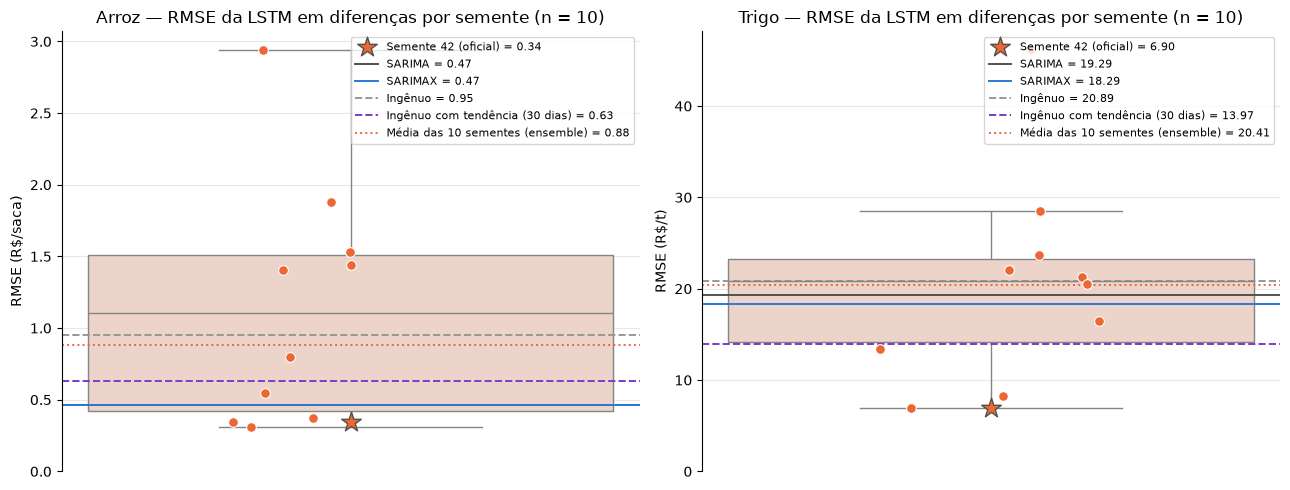

In [6]:
CORES_REF = {"SARIMA": "#52514e", "SARIMAX": "#2a78d6", "Ingênuo": "#9a9893",
             "Ingênuo com tendência (30 dias)": "#7a3cc8", "Média das 10 sementes (ensemble)": "#eb6834"}
ESTILO_REF = {"SARIMA": "-", "SARIMAX": "-", "Ingênuo": "--", "Ingênuo com tendência (30 dias)": "--",
              "Média das 10 sementes (ensemble)": ":"}

fig, eixos = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (cultura, cfg) in zip(eixos, CULTURAS.items()):
    g = resultados.query("cultura == @cultura")
    sns.boxplot(y=g["RMSE"], color="#f3d2c4", width=0.35, showfliers=False, ax=ax)
    sns.stripplot(y=g["RMSE"], color="#eb6834", size=7, jitter=0.08, edgecolor="white", linewidth=0.8, ax=ax)
    s42 = g.query("semente == 42")["RMSE"].iloc[0]
    ax.scatter([0], [s42], marker="*", s=220, color="#eb6834", edgecolor="#52514e", zorder=5, label=f"Semente 42 (oficial) = {s42:.2f}")
    for nome, valor in refs[cultura].items():
        ax.axhline(valor, color=CORES_REF[nome], ls=ESTILO_REF[nome], lw=1.4, label=f"{nome} = {valor:.2f}")
    ax.set_title(f"{cultura.capitalize()} — RMSE da LSTM em diferenças por semente (n = {len(g)})")
    ax.set_ylabel(f"RMSE ({cfg['unidade']})")
    ax.set_xticks([])
    ax.set_ylim(0, None)
    ax.grid(alpha=0.3, axis="y")
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/lstm_sementes_rmse.png", dpi=300)
plt.show()

## 4. Trajetórias previstas por semente

Cada linha fina é a previsão recursiva de 30 dias de uma semente; a linha tracejada é a média das 10 (*ensemble*). A dispersão entre
as linhas mostra quanto a **inclinação projetada** — que, como visto nos notebooks de cada cultura, é o que determina o erro em 30 dias — depende
da inicialização da rede.

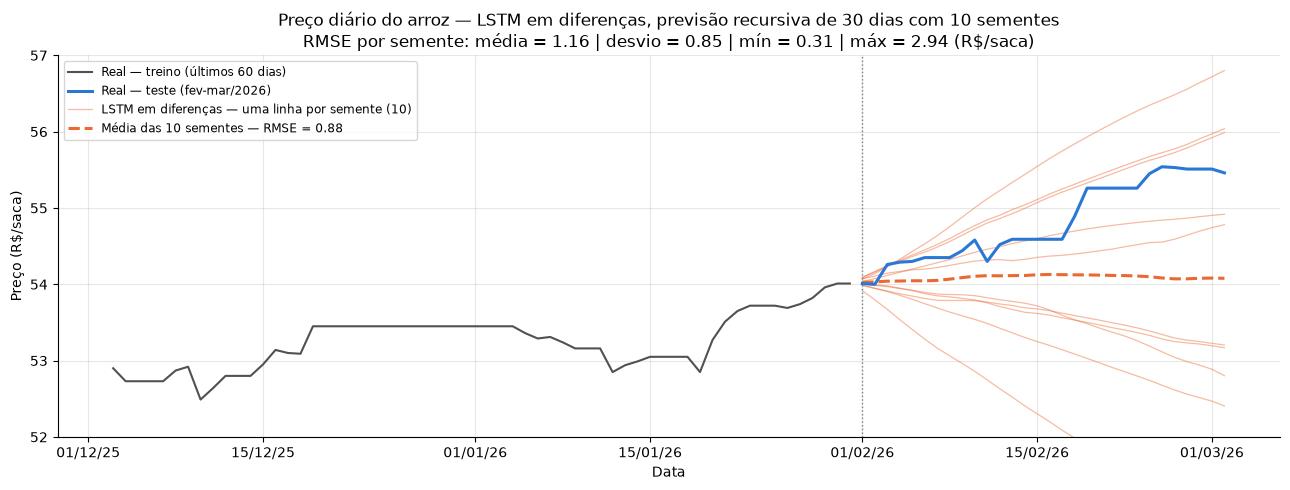

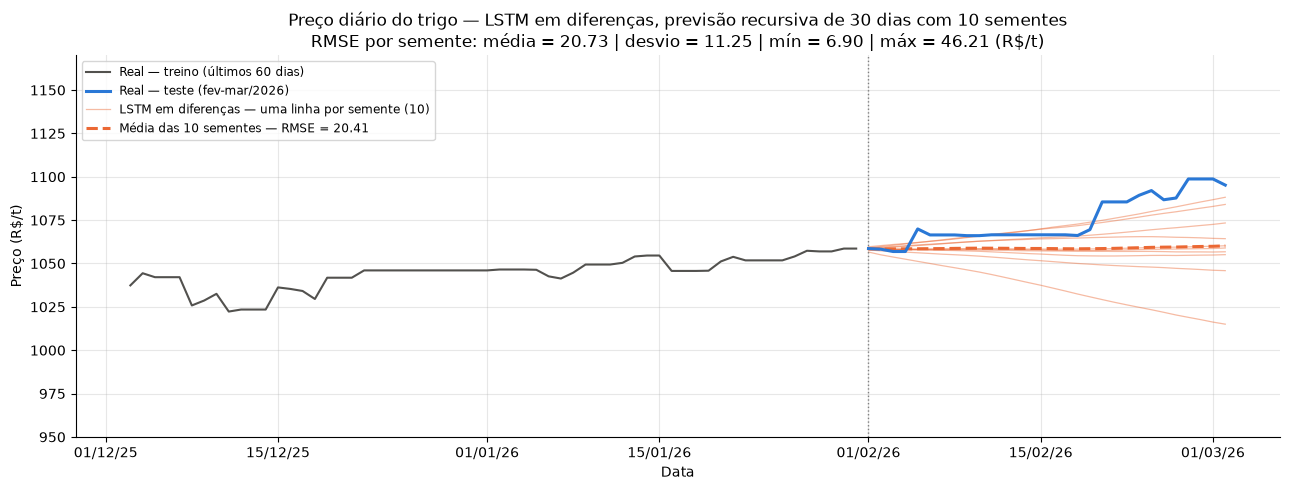

In [7]:
for cultura, cfg in CULTURAS.items():
    p = PREP[cultura]
    y_teste = p["teste"][ALVO]
    contexto = p["treino"][ALVO].iloc[-60:]

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 60 dias)")
    ax.plot(y_teste,  color="#2a78d6", lw=2.2, label="Real — teste (fev-mar/2026)", zorder=4)
    for i, s in enumerate(SEMENTES):
        ax.plot(trajetorias[(cultura, s)], color="#eb6834", lw=0.9, alpha=0.45,
                label="LSTM em diferenças — uma linha por semente (10)" if i == 0 else None)
    ens = trajetorias[(cultura, "ensemble")]
    ax.plot(ens, color="#eb6834", lw=2.2, ls="--", label=f"Média das 10 sementes — RMSE = {refs[cultura]['Média das 10 sementes (ensemble)']:.2f}")
    ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)
    g = resultados.query("cultura == @cultura")["RMSE"]
    ax.set_title(f"Preço diário do {cultura} — LSTM em diferenças, previsão recursiva de 30 dias com 10 sementes\n"
                 f"RMSE por semente: média = {g.mean():.2f} | desvio = {g.std():.2f} | mín = {g.min():.2f} | máx = {g.max():.2f} ({cfg['unidade']})")
    ax.set_xlabel("Data")
    ax.set_ylabel(f"Preço ({cfg['unidade']})")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
    ax.set_ylim(*cfg["ylim"])
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", fontsize=8.5)
    plt.tight_layout()
    plt.savefig(f"{PASTA_SAIDA}/lstm_sementes_trajetorias_{cultura}.png", dpi=300)
    plt.show()

## 5. Exportação

- `metricas_lstm_sementes.csv` — uma linha por cultura e semente (RMSE, MAE, MAPE, inclinação, ganho na validação, épocas);
- `resumo_lstm_sementes.csv` — média, desvio, mínimo, mediana e máximo por cultura, contagem de sementes que superam cada referência e RMSE do *ensemble*;
- `previsoes_lstm_sementes_<cultura>.csv` — trajetórias diárias de cada semente e do *ensemble*;
- `metricas_lstm_<cultura>.csv` — **métrica oficial da LSTM** de cada cultura: média de RMSE, MAE e MAPE nas 10 sementes, com os desvios-padrão.
  É o arquivo lido pelas tabelas comparativas dos notebooks de cada cultura.

In [8]:
resultados.round(4).to_csv(f"{PASTA_SAIDA}/metricas_lstm_sementes.csv", index=False)
resumo.round(4).to_csv(f"{PASTA_SAIDA}/resumo_lstm_sementes.csv")

# Métrica oficial da LSTM de cada cultura: média das 10 sementes (com desvio-padrão)
for cultura, g in resultados.groupby("cultura", sort=False):
    pd.DataFrame({"modelo": ["LSTM(64) em diferenças, recursiva — média de 10 sementes"],
                  "RMSE": [g["RMSE"].mean()], "MAE": [g["MAE"].mean()], "MAPE": [g["MAPE"].mean()],
                  "RMSE_desvio": [g["RMSE"].std()], "MAE_desvio": [g["MAE"].std()], "MAPE_desvio": [g["MAPE"].std()],
                  "n_sementes": [len(g)]}).round(4).to_csv(f"{PASTA_SAIDA}/metricas_lstm_{cultura}.csv", index=False)
for cultura in CULTURAS:
    tab = pd.DataFrame({"real": PREP[cultura]["teste"][ALVO],
                        **{f"semente_{s}": trajetorias[(cultura, s)] for s in SEMENTES},
                        "ensemble": trajetorias[(cultura, "ensemble")]})
    tab.rename_axis("data").round(4).to_csv(f"{PASTA_SAIDA}/previsoes_lstm_sementes_{cultura}.csv", date_format="%Y-%m-%d")

for arquivo in ["metricas_lstm_sementes.csv", "resumo_lstm_sementes.csv", "previsoes_lstm_sementes_arroz.csv",
                "previsoes_lstm_sementes_trigo.csv", "lstm_sementes_rmse.png",
                "lstm_sementes_trajetorias_arroz.png", "lstm_sementes_trajetorias_trigo.png",
                "metricas_lstm_arroz.csv", "metricas_lstm_trigo.csv"]:
    caminho = os.path.join(PASTA_SAIDA, arquivo)
    print(f"{caminho:<46} salvo: {os.path.exists(caminho)}  ({os.path.getsize(caminho):,} bytes)")

outputs\metricas_lstm_sementes.csv             salvo: True  (1,090 bytes)
outputs\resumo_lstm_sementes.csv               salvo: True  (456 bytes)
outputs\previsoes_lstm_sementes_arroz.csv      salvo: True  (3,259 bytes)
outputs\previsoes_lstm_sementes_trigo.csv      salvo: True  (3,979 bytes)
outputs\lstm_sementes_rmse.png                 salvo: True  (201,512 bytes)
outputs\lstm_sementes_trajetorias_arroz.png    salvo: True  (314,539 bytes)
outputs\lstm_sementes_trajetorias_trigo.png    salvo: True  (237,034 bytes)


## Conclusão

**A semente 42 foi a mais favorável das 10 no trigo e a segunda mais favorável no arroz.** O resultado dos notebooks de cada cultura não
representa o desempenho esperado da LSTM:

| | Arroz (R\$/saca) | Trigo (R\$/t) |
|---|---|---|
| RMSE semente 42 (notebook oficial) | 0,34 | 6,90 |
| **RMSE média ± desvio (10 sementes)** | **1,16 ± 0,85** | **20,73 ± 11,25** |
| RMSE mínimo – máximo | 0,31 – 2,94 | 6,90 – 46,21 |
| RMSE da média das 10 sementes (*ensemble*) | 0,88 | 20,41 |
| SARIMA / SARIMAX | 0,47 / 0,47 | 19,29 / 18,29 |
| Ingênuo / ingênuo com tendência (30 dias) | 0,95 / 0,63 | 20,89 / 13,97 |
| Sementes melhores que o SARIMAX | 3 de 10 | 4 de 10 |
| Sementes melhores que o ingênuo | 5 de 10 | 5 de 10 |

- **A vantagem da LSTM sobre o SARIMA/SARIMAX não se sustenta.** Em média, a LSTM em diferenças erra **2,5 vezes mais** que o SARIMAX no arroz
  e **13% mais** no trigo. Só 3 (arroz) e 4 (trigo) das 10 sementes superam o SARIMAX, e metade delas perde até para a previsão ingênua.
- **A inclinação projetada é um artefato da inicialização.** Ela muda de **sinal** conforme a semente: de −0,11 a +0,09 R\$/saca por dia no arroz
  e de −1,45 a +0,99 R\$/t por dia no trigo. Como os notebooks de cada cultura mostraram, é essa inclinação que determina o erro em 30 dias; ela
  não é aprendida de forma consistente a partir dos dados.
- **A rede quase não aprende a variação diária.** O ganho médio na validação sobre "prever sempre a variação média" é de 0,9% (arroz) e 2,9% (trigo);
  em 4 das 10 sementes do arroz o ganho é negativo — e são justamente 3 das 4 melhores no teste (42, 8 e 9), o que reforça que o acerto
  em 30 dias não vem de capacidade preditiva aprendida.
- **O *ensemble* não resolve.** Como as inclinações têm sinais opostos, a média das 10 sementes fica quase plana e se aproxima do ingênuo
  (arroz 0,88; trigo 20,41), ainda pior que o SARIMAX nas duas culturas.

**Implicação para o TCC:** o desempenho da LSTM deve ser reportado como **média ± desvio entre sementes**, e não pelo resultado de uma única semente.
Com essa correção, a conclusão do trabalho muda: em previsão de 30 dias com horizonte fechado, a LSTM (nesta arquitetura e com estes dados)
**não supera** os modelos estatísticos — o SARIMAX é o modelo mais preciso e mais estável nas duas culturas, e a LSTM tem desempenho comparável
ao ingênuo, com alta variância. A diferenciação do alvo continua sendo uma contribuição válida: ela elimina o colapso da previsão recursiva
(no trigo, de 59,28 para 20,73 em média), mas não cria capacidade preditiva que a rede não tem.
